## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

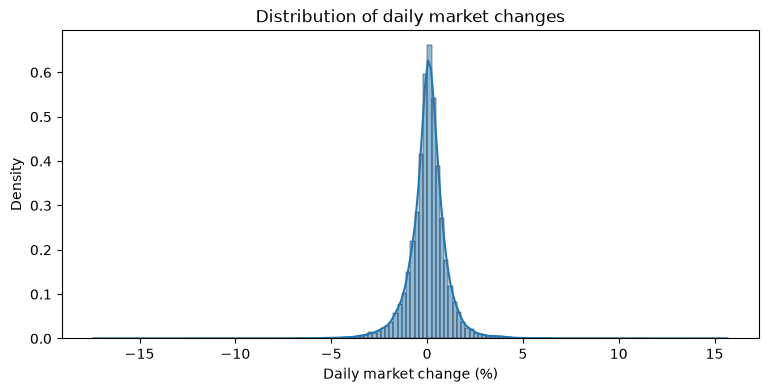

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

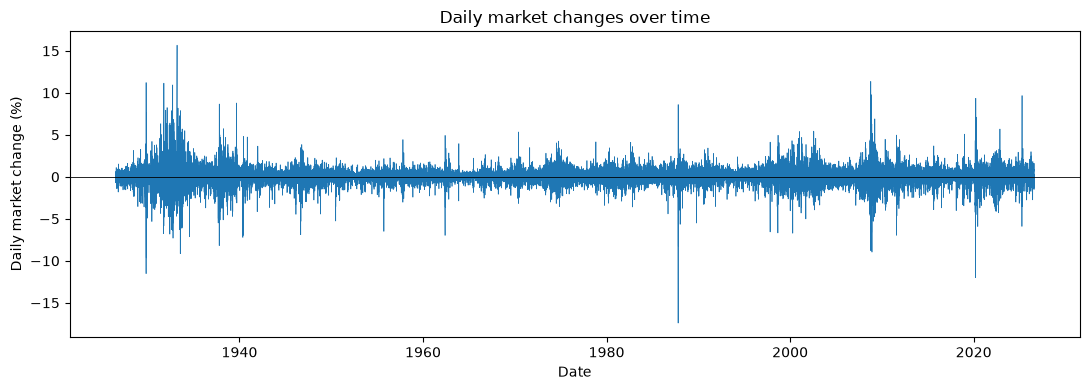

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Part One: Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [4]:
# make a categorical column "direction_t" 
# direction_categories =['Down/ flat', 'Up']
direction_categories = ['Down / flat', 'Up']
np.where(df['market_return_pct'] > 0, 'Up', 'Down / flat')

df['direction_t'] = pd.Categorical(
    np.where(df['market_return_pct'] > 0, 'Up', 'Down / flat'),
    categories=direction_categories,
    ordered=True,
)

In [6]:
# make a categorical column "direction_tp1" for the next trading day
df['direction_tp1'] = df['direction_t'].shift(-1)

In [7]:
df[["direction_t", "direction_tp1" ]]

,direction_t,direction_tp1
0,Up,Up
1,Up,Up
2,Up,Up
3,Up,Up
4,Up,Down / flat
...,...,...
26291,Up,Up
26292,Up,Down / flat
26293,Down / flat,Up
26294,Up,Up


In [8]:
pd.crosstab(df['direction_t'], df['direction_tp1'],normalize = True, margins = True)

direction_tp1,Down / flat,Up,All
direction_t,,,
Down / flat,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


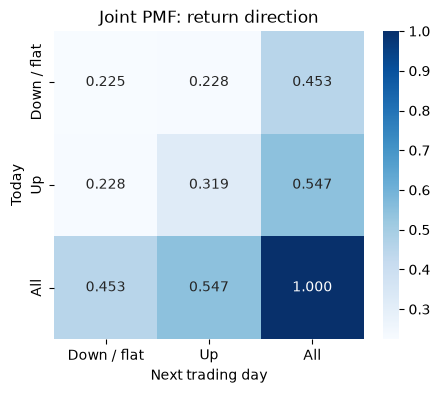

In [9]:
# Plot the joint PMF
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df['direction_t'], df['direction_tp1'],normalize = True, margins = True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

In [10]:
# Plot the conditional PMF
pd.crosstab(df['direction_t'], df['direction_tp1'], normalize ='index')

direction_tp1,Down / flat,Up
direction_t,,
Down / flat,0.496221,0.503779
Up,0.416974,0.583026


<div class='alert alert-info'><b>Answer the following:</b>

- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

</div>

The up transitions are more common than down transitions the probability of market going up tomorrow given today is 0.50377.  if the market went up today the probability of it going up tomorrow is 0.58302. both cases up is more likely

We are more likely to transition to an up day from an Uu day. The probability is higher after an Up day, compared with 0.50377 after a Down day a difference of approximately 8.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- Subtract the marginal PMF of tomorrow's state from each row of the conditional PMF, and plot the result as a heatmap. If tomorrow's state were independent of today's, every row of the conditional PMF would equal this marginal. Which transitions are more likely than independence predicts, and which are less likely? Does knowing today's state change the forecast for tomorrow?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [11]:
return_categories = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
# df['return_bin'] =  pd.cut(df['market_return_pct'], bins =[-np.inf, -1, -0.1 .0.1, 1,no.inf], labels = return_categories)
df['return_bin'] = pd.cut(df['market_return_pct'],bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf],labels=return_categories)


In [12]:
df['return_bin'].value_counts()

return_bin
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

In [13]:
#make y_t and y_tp1 columns for the return bins
df['y_t'] = df['return_bin']
df['y_tp1'] = df['return_bin'].shift(-1)

In [14]:
counts = pd.crosstab(df['y_t'], df['y_tp1'])

In [15]:
joint = pd.crosstab(df['y_t'],df['y_tp1'],normalize=True, margins= True)
joint

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


<div class='alert alert-info'><b>Answer the following:</b>

- How many days fall into each of the five bins?  (use value_counts)
- Which are the most or least common?
  
  </div>

Small gain is the most common category 9785 days Large loss is the least common, with 2,759 days.
* Small gain    9785
* Small loss    7452
* Near zero     3441
* Large gain    2859
* Large loss    2759


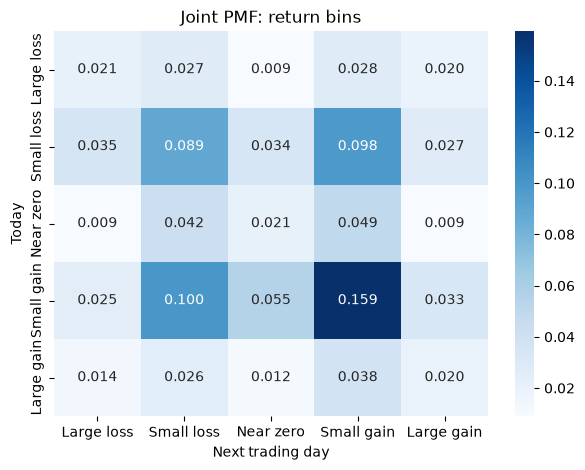

In [18]:
#joint PMF with marginals
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(pd.crosstab(df['y_t'], df['y_tp1'], normalize=True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return bins')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Which transitions are most likely to occur? 

</div>

small gain to another small gain

In [22]:
#conditional PMF 
conditional_pmf = pd.crosstab(df['y_t'],df['y_tp1'],normalize='index'
)

conditional_pmf

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


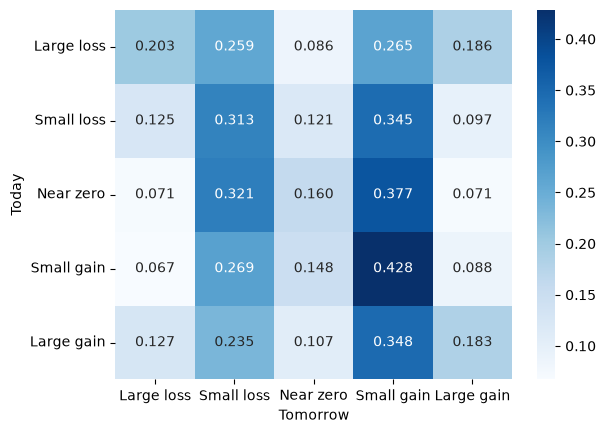

In [24]:
sns.heatmap(conditional_pmf, annot=True, fmt='.3f', cmap='Blues')
plt.xlabel('Tomorrow')
plt.ylabel('Today')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- For each current state, which two future states are the most likely? 
- Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? 
- Is it relatively easy or difficult to predict the next state?
</div>

1. Large Loss
 * 0.265  Small gain
 * 0.259  Small loss
2. Small Loss
 * Small loss
 * Small Gain
3. Near zero
 * Small loss
 * Small Gain
4. Small gain
 * Small loss
 * Small gain
5. Large gain 
 * Small loss
 * Small gain

Some bins are closer to 0.2 while some bins vary substantiallly this cannot be called a uniform distribution and none of them are particularly close.

From the conditional table alone i would say predicting is difficult as even the most likely bin for next day has a probability is below 50% so there is uncertainty of what can occur tomorrow. 



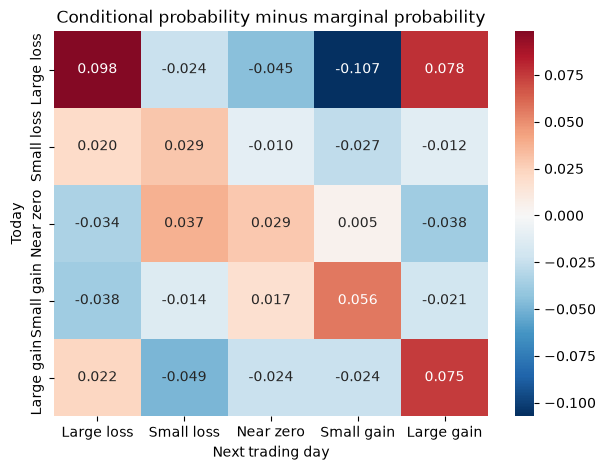

In [25]:
# marginal PMF of tomorrow's state: sum the joint PMF (without margins) down each column
next_state_pmf = next_state_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True).sum(axis=0)
next_state_pmf

conditional = pd.crosstab(df['y_t'], df['y_tp1'], normalize="index")
# subtract it from each row of the conditional PMF and plot as a heatmap
# hint: use .sub(next_state_pmf, axis='columns'), and a diverging colormap such as cmap='RdBu_r' with center=0
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(conditional.sub(next_state_pmf, axis='columns'),
            annot=True, fmt='.3f', center=0, cmap='RdBu_r', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today',
       title='Conditional probability minus marginal probability')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Which transitions are more likely than independence predicts, and which are less likely?
- Does knowing today's state change the forecast for tomorrow?
- How is this comparison different from comparing each row to a uniform PMF with probability .2?
</div>

All transitions with positive differences is mire likel than predicts and transitions with negative dofferemce is less llikely.
For example, 
* more likely:
 Large loss → Large loss 
 Small gain → Small gain
* less likely 
 Large loss → Small gain 

Yes it does as  the forecast for tomorrow because the differences between conditional and marginal probabilities are not all zero for them to be independent.(Althrouh some are close to zero)

A uniform PMF compares each probability to 0.2 to check if the events are uniform  are if they are erqually likely.

The marginal PMF uses the actual probabilities of each outcome. Comparing conditional and marginal probabilities helps us check if the 2 states probabilities are independent.



In [26]:
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)
# use groupby and describe/mean to get the conditional expectation of the next day's return given today's return bin y_t
df.groupby('y_t')['market_return_pct_tp1'].describe()

/var/folders/c1/71j1k1p927b056ntwl51240h0000gn/T/ipykernel_3400/2658844929.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('y_t')['market_return_pct_tp1'].describe()


,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


<div class='alert alert-info'><b>Answer the following:</b>

- Given the current state, what are the expected percent returns for tomorrow? 
- How do the min and max values for tomorrow vary across states? 
- Which states have the highest standard deviation for tomorrow's percent returns? 
- Describe any patterns in the volatility you notice.
</div>


They are the means
Large loss	−0.0383
Small loss	−0.0438
Near zero	+0.0150
Small gain	+0.1068
Large gain	+0.1631

Expected returns are negative after losses and positive after gains.
Most are approximately zero.

Large loss (1.721) has the highest standard deviation, followed by Large gain (1.384)

Volatility can be noticed after extreme markets like larrge loss and large gain characterized by a large standard deviation that suggests inconsistency in the market return.  Large gains and losses show markedly larger standard deviations than the other three bins.  The range of each condition (difference between the max and min can also be used as a measure of volatility; it is somewhat similar to the standard deviation).  The range is larger for large losses and gains than for the other three conditions. These statistics suggest that large losses and gains today, predict large losses and gains the next day.  A large gain can predict a large gain, but also a large loss.  So it predicts the magnitude of the next day returns but not the direction. The degree of fluctuation and amount is higher on these days, making the prediction more uncertain.



### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [27]:
#cut into 21 equal-sized bins and make y_t and y_tp1 columns for the return bins
bins = 21
labels = [f"Q{i+1}" for i in range(bins)]

df['y_t'] = pd.qcut(df['market_return_pct'], q=bins, labels=labels)
df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts(sort=False).rename('Trading days').to_frame().T

y_t,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20,Q21
Trading days,1255,1253,1286,1280,1230,1226,1371,1206,1198,1331,...,1223,1294,1223,1310,1193,1211,1283,1225,1250,1238


In [29]:
#joint PMF with marginals for the 21 quantile bins + plot as heatmap
bins = 21
labels = [f"Q{i+1}" for i in range(bins)]

df['y_t'] = pd.qcut(df['market_return_pct'], q=bins, labels=labels)
df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts(sort=False).rename('Trading days').to_frame().T

y_t,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20,Q21
Trading days,1255,1253,1286,1280,1230,1226,1371,1206,1198,1331,...,1223,1294,1223,1310,1193,1211,1283,1225,1250,1238


In [31]:
quantile_joint = pd.crosstab(
    df['y_t'], df['y_tp1'], normalize=True, margins = False
)

<Axes: xlabel='y_tp1', ylabel='y_t'>

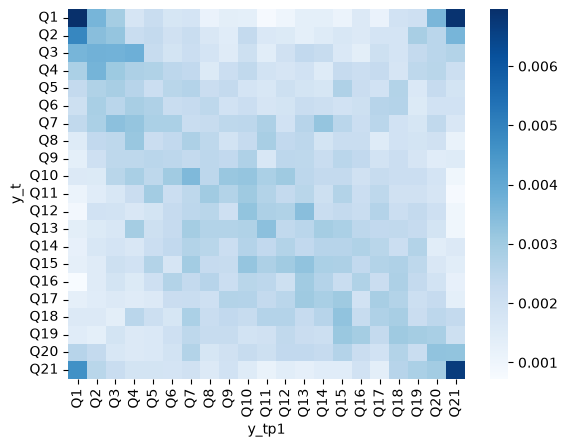

In [32]:
sns.heatmap(quantile_joint, cmap='Blues')

<Axes: xlabel='y_tp1', ylabel='y_t'>

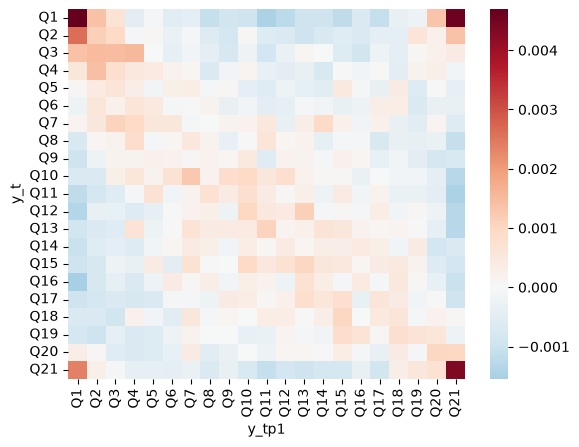

In [33]:
sns.heatmap(quantile_joint - 1/bins**2, cmap='RdBu_r', center=0)

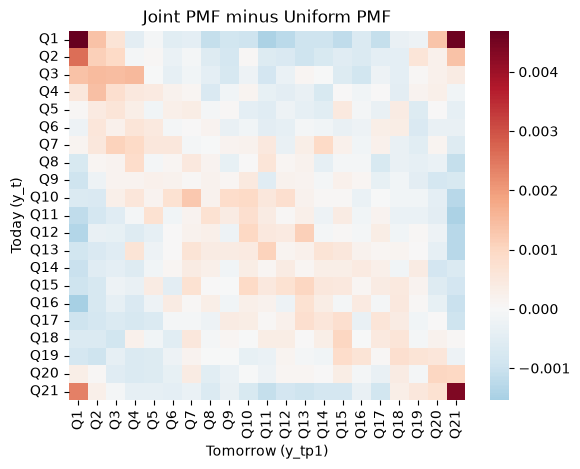

In [34]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.
sns.heatmap(
    quantile_joint - 1/bins**2,
    cmap='RdBu_r',
    center=0
)

plt.xlabel('Tomorrow (y_tp1)')
plt.ylabel('Today (y_t)')
plt.title('Joint PMF minus Uniform PMF')
plt.show()


<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

corners of the heatmap are darker red  showing that extreme returns are followed by other extreme returns more often It seems that the volatility is driven by the extreme ends of the large losses and gains at the largest and smallest quantile bins in the corners of the heatmap 

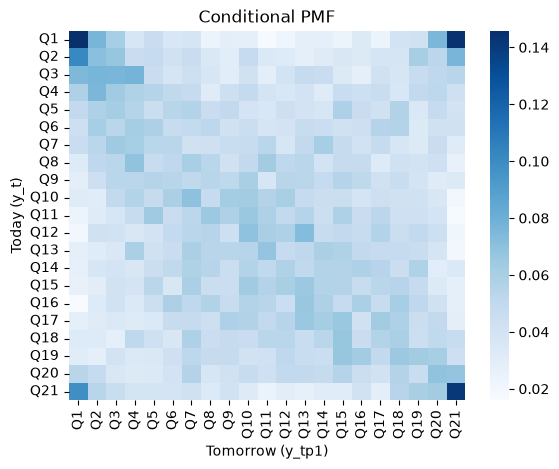

In [38]:
# Compute conditional PMF
quantile_conditional = pd.crosstab(
    df['y_t'],
    df['y_tp1'],
    normalize='index'
)

# Plot conditional PMF
sns.heatmap(
    quantile_conditional,
    cmap='Blues'
)

plt.xlabel('Tomorrow (y_tp1)')
plt.ylabel('Today (y_t)')
plt.title('Conditional PMF')
plt.show()

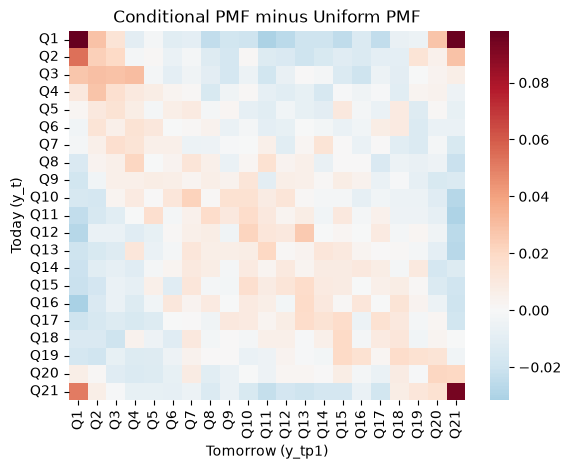

In [39]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.
# Subtract the uniform PMF and plot
sns.heatmap(
    quantile_conditional - 1/bins,
    cmap='RdBu_r',
    center=0
)

plt.xlabel('Tomorrow (y_tp1)')
plt.ylabel('Today (y_t)')
plt.title('Conditional PMF minus Uniform PMF')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

The four corners are darker red showing that extreme losses and gains are more likely to be followed by other extreme returns again so larger market movements tend to be followed by larger market movements
 graph shows a slightly greater likelihood the next day returns being similar to the previous days returns as a result of the downward diagonal in the heatmap.

In [40]:
# compute the next day's min, mean, and max conditional on each bin
quantile_stats = df.groupby('y_t', observed=False)['market_return_pct_tp1'].agg(
    ['min', 'mean', 'max']
)

quantile_stats

,min,mean,max
y_t,,,
Q1,-17.41,-0.013713,11.22
Q2,-7.36,-0.076712,6.36
Q3,-8.79,-0.097084,11.36
Q4,-8.28,-0.058594,6.16
Q5,-6.89,-0.024211,4.56
Q6,-11.23,-0.022692,6.37
Q7,-3.94,-0.030241,7.37
Q8,-3.40,-0.014303,4.76
Q9,-6.00,0.025860,5.49


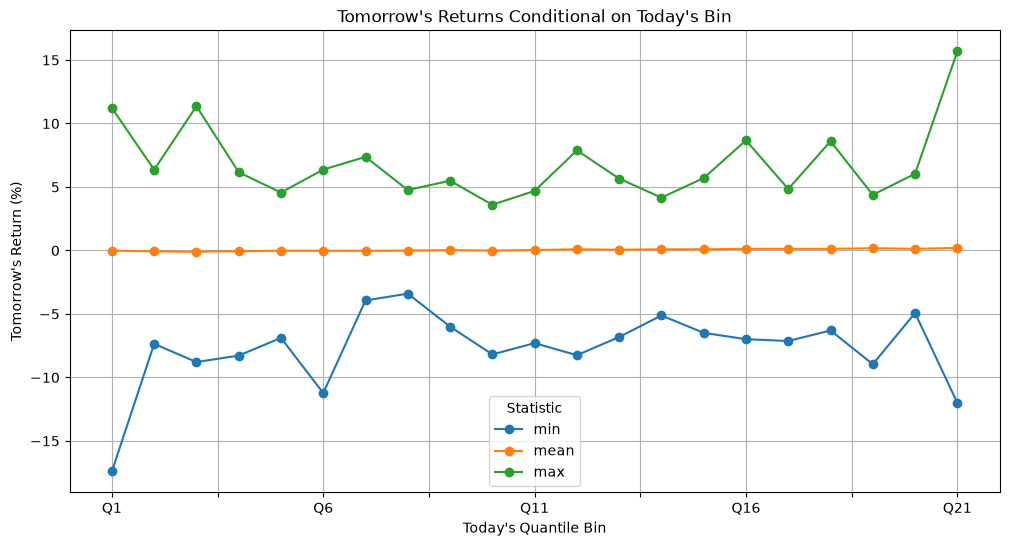

In [41]:
#plot as lines on a graph against the bins
quantile_stats.plot(
    kind='line',
    figsize=(12, 6),
    marker='o'
)

plt.xlabel("Today's Quantile Bin")
plt.ylabel("Tomorrow's Return (%)")
plt.title("Tomorrow's Returns Conditional on Today's Bin")
plt.legend(title="Statistic")
plt.grid(True)
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

The average return for tomorrow generally increases from Q1 to Q21. The minimum and maximum returns are also more extreme at Q1 and Q21, while the middle bins tend to have smaller ranges This suggests that large market movements are often followed by greater volatility,regardless of whether the returns are positive or negative.

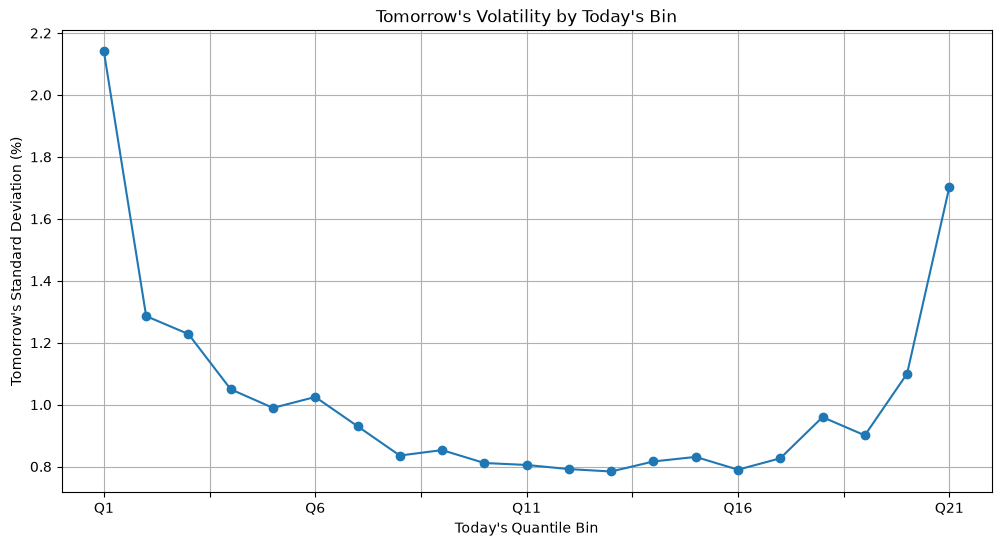

In [42]:
#compute the next day's standard deviation, and plot it as a line graph against the bins. 

quantile_std = df.groupby('y_t', observed=False)['market_return_pct_tp1'].std()

# Plot as a line graph
quantile_std.plot(
    kind='line',
    figsize=(12, 6),
    marker='o'
)

plt.xlabel("Today's Quantile Bin")
plt.ylabel("Tomorrow's Standard Deviation (%)")
plt.title("Tomorrow's Volatility by Today's Bin")
plt.grid(True)
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

The graph shows a U shaped pattern. Standard deviation is highest after extreme losses (Q1) and extreme gains (Q21) while the middle bins have lower standard deviations hence reflecting more. volaility at the extreme ends

<div class='alert alert-info'><b>Answer the following:</b>

How easy is it to predict the market?
</div>

The ease of predicting the market depends on whether or not one is interested in predicting the size of the change in the market, the direction of the change or both. The market has a high degree of volatility in that during volatile periods, the market swings from large gains and losses to large gains and losses.  However, the direction could either be a gain or a loss, we just know that the magnitude of the change is big.  Consequently, for those trying to play the market, if a large gain or loss has occurred, then keeping your money in the market is high risk of a large loss, but also high reward of a large gain.  Therefore, predicting the size of market fluctuations may be easier than predicting their exact direction of where it may go next is hard